# Lecture 6: Exploratory Data Analysis

Simplified lecture companion: Student Performance. Run cells from top to bottom. Code comments and explanations are in English. The presentation is unchanged.

Google Drive access below follows the original notebook. Alternatively, upload Student_Performance.csv to the Colab Files panel and use its local filename when reading the CSV. Outputs have been cleared so they match your next run.

## 1. Load and inspect data

Keep the established Google Drive workflow. Authentication is interactive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

print("Packages loaded.")

Packages loaded.


In [3]:
project_dir = Path("/content/drive/MyDrive/2026_2027/PyR/Topic_6")
data_path = project_dir/"Student_Performance.csv"

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")

df = pd.read_csv(data_path)

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head(10))

Dataset loaded: 10000 rows, 6 columns


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


In [4]:
print("DATASET DIMENSIONS")
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")

print("\nFIRST FIVE ROWS")
display(df.head())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES PER COLUMN")
display(df.isna().sum().to_frame(name="Missing values"))

print("\nDUPLICATE ROWS")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\nSUMMARY OF ALL COLUMNS")
display(df.describe(include="all").T)

print("\nCATEGORICAL VALUE COUNTS")
display(df["Extracurricular Activities"].value_counts(dropna=False))

DATASET DIMENSIONS
Rows: 10000, columns: 6

FIRST FIVE ROWS


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0



DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

MISSING VALUES PER COLUMN


,Missing values
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0



DUPLICATE ROWS
Number of duplicate rows: 127

SUMMARY OF ALL COLUMNS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours Studied,10000.0,NaN,NaN,NaN,4.9929,2.589309,1.0,3.0,5.0,7.0,9.0
Previous Scores,10000.0,NaN,NaN,NaN,69.4457,17.343152,40.0,54.0,69.0,85.0,99.0
Extracurricular Activities,10000,2,No,5052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,10000.0,NaN,NaN,NaN,6.5306,1.695863,4.0,5.0,7.0,8.0,9.0
Sample Question Papers Practiced,10000.0,NaN,NaN,NaN,4.5833,2.867348,0.0,2.0,5.0,7.0,9.0
Performance Index,10000.0,NaN,NaN,NaN,55.2248,19.212558,10.0,40.0,55.0,71.0,100.0



CATEGORICAL VALUE COUNTS


,count
Extracurricular Activities,
No,5052
Yes,4948


## 2. Central tendency

Report all modes when several values have the same highest frequency. R mode() describes storage type, so we use a short statistical_mode() function.

In [5]:
numeric_df = df.select_dtypes(include="number")
central_tendency = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median()
})
central_tendency["Modes"] = [
    ", ".join(map(str, numeric_df[column].mode()))
    for column in numeric_df
]
display(central_tendency.round(3))
print("Most frequent category:", df["Extracurricular Activities"].mode().tolist())

,Mean,Median,Modes
Hours Studied,4.993,5.0,1
Previous Scores,69.446,69.0,54
Sleep Hours,6.531,7.0,8
Sample Question Papers Practiced,4.583,5.0,6
Performance Index,55.225,55.0,67.0


Most frequent category: ['No']


## 3. Effect of an extreme value

Replacing 8 with 28 changes the mean from 4 to 8. Median and mode remain 3.

In [6]:
original = pd.Series([2, 3, 3, 4, 8])
modified = pd.Series([2, 3, 3, 4, 28])
for x in [original, modified]:
    print("Values:", x.tolist())
    print("Mean:", x.mean(), "Median:", x.median(), "Modes:", x.mode().tolist())

Values: [2, 3, 3, 4, 8]
Mean: 4.0 Median: 3.0 Modes: [3]
Values: [2, 3, 3, 4, 28]
Mean: 8.0 Median: 3.0 Modes: [3]


## 4. Variability and five-number summary

Both languages use sample variance (n - 1 denominator). Default quantiles agree: linear interpolation in pandas and type 7 in R. Summaries omit missing values separately for each variable.

In [7]:
q1 = numeric_df.quantile(0.25)
q3 = numeric_df.quantile(0.75)

summary_table = pd.DataFrame({
    "Count": numeric_df.count(),
    "Mean": numeric_df.mean(),
    "Variance": numeric_df.var(),
    "SD": numeric_df.std(),
    "Min": numeric_df.min(),
    "Q1": q1,
    "Median": numeric_df.median(),
    "Q3": q3,
    "Max": numeric_df.max(),
    "Range": numeric_df.max() - numeric_df.min(),
    "IQR": q3 - q1
})

display(summary_table.round(3))

,Count,Mean,Variance,SD,Min,Q1,Median,Q3,Max,Range,IQR
Hours Studied,10000,4.993,6.705,2.589,1.0,3.0,5.0,7.0,9.0,8.0,4.0
Previous Scores,10000,69.446,300.785,17.343,40.0,54.0,69.0,85.0,99.0,59.0,31.0
Sleep Hours,10000,6.531,2.876,1.696,4.0,5.0,7.0,8.0,9.0,5.0,3.0
Sample Question Papers Practiced,10000,4.583,8.222,2.867,0.0,2.0,5.0,7.0,9.0,9.0,5.0
Performance Index,10000,55.225,369.122,19.213,10.0,40.0,55.0,71.0,100.0,90.0,31.0


## 5. Same mean, different spread

Both means equal 5; variances are 1 and 25; standard deviations are 1 and 5.

In [8]:
for x in [pd.Series([4, 5, 6]), pd.Series([0, 5, 10])]:
    print("Values:", x.tolist())
    print("Mean:", x.mean(), "Variance:", x.var(), "SD:", x.std(), "Range:", x.max() - x.min())

Values: [4, 5, 6]
Mean: 5.0 Variance: 1.0 SD: 1.0 Range: 2
Values: [0, 5, 10]
Mean: 5.0 Variance: 25.0 SD: 5.0 Range: 10


## 6. Quantiles: values 1 to 9

Expected five-number summary: 1, 3, 5, 7, 9.

In [9]:
x = pd.Series(range(1, 10))
print(x.quantile([0, 0.25, 0.5, 0.75, 1]))

0.00    1.0
0.25    3.0
0.50    5.0
0.75    7.0
1.00    9.0
dtype: float64


## 7. Histograms

Inspect symmetry, tails, peaks and gaps. Red and green lines may overlap. Bin edges are matched between environments.

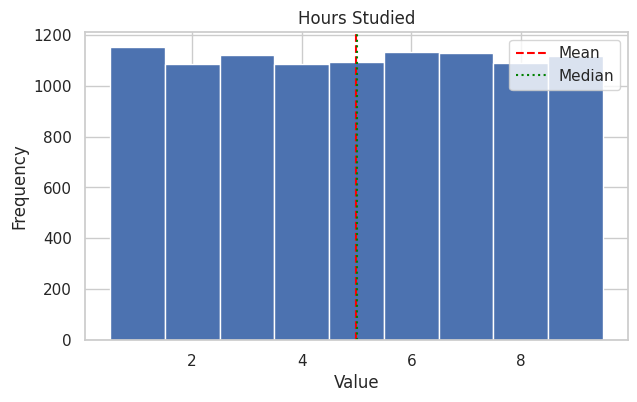

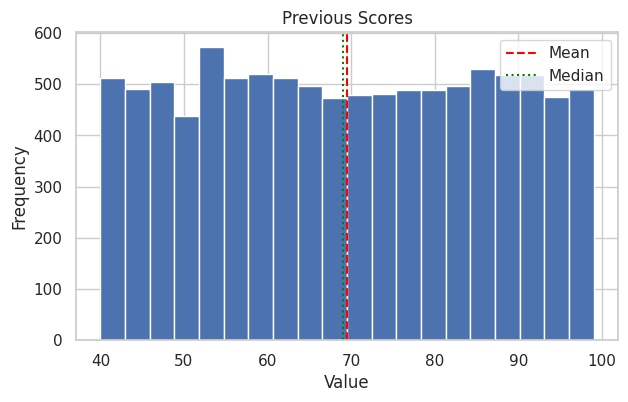

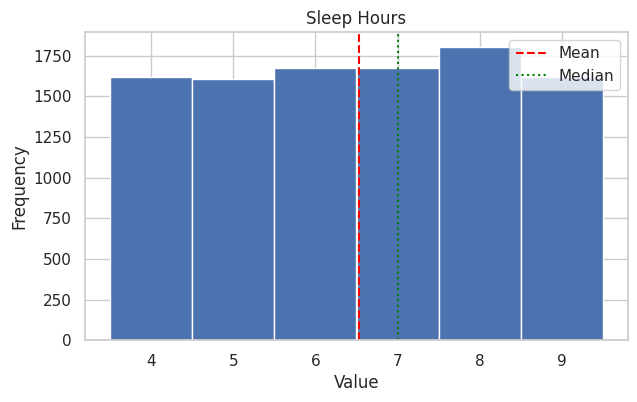

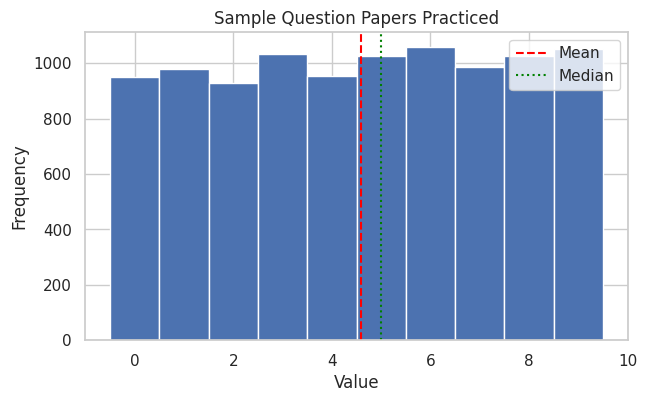

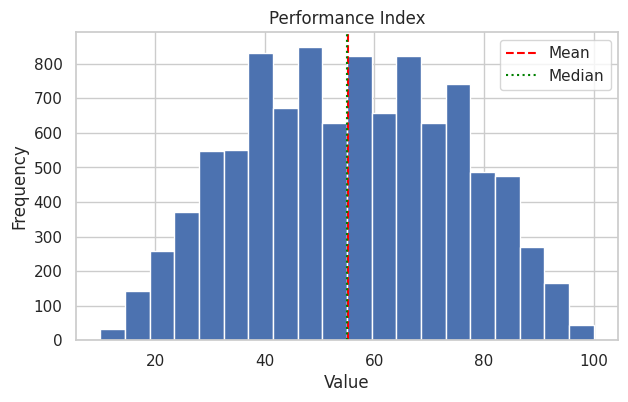

In [10]:
for column in numeric_df:
    x = numeric_df[column].dropna()
    # Align bins with integer values when there are few distinct values.
    if x.nunique() <= 15 and (x % 1 == 0).all():
        bins = np.arange(x.min() - 0.5, x.max() + 1, 1)
    else:
        bins = np.linspace(x.min(), x.max(), 21)
    plt.figure(figsize=(7, 4))
    plt.hist(x, bins=bins, edgecolor="white")
    plt.axvline(x.mean(), color="red", linestyle="--", label="Mean")
    plt.axvline(x.median(), color="green", linestyle=":", label="Median")
    plt.title(column)
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

## 8. Category frequencies

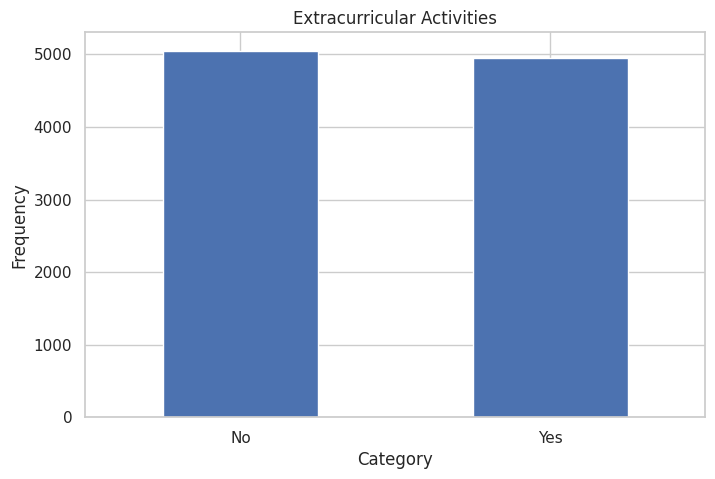

In [11]:
df["Extracurricular Activities"].value_counts(dropna=False).plot.bar(rot=0)
plt.title("Extracurricular Activities")
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.show()

## 9. Boxplots

Points outside whiskers are potential outliers, not automatically errors. R base boxplot uses Tukey hinges; for small samples they can differ from type-7 quartiles. The explicit IQR screening below uses matching quartiles in both languages.

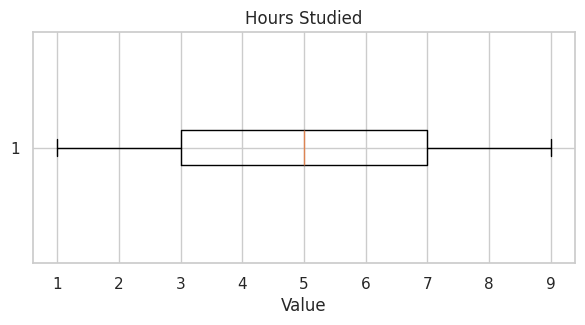

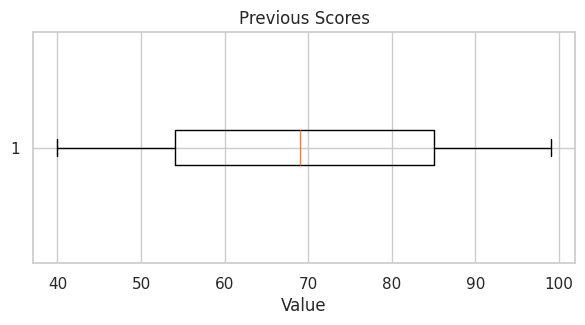

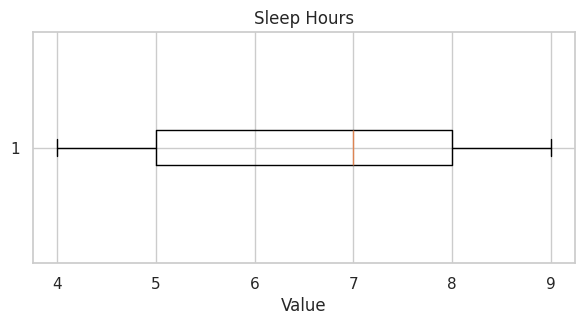

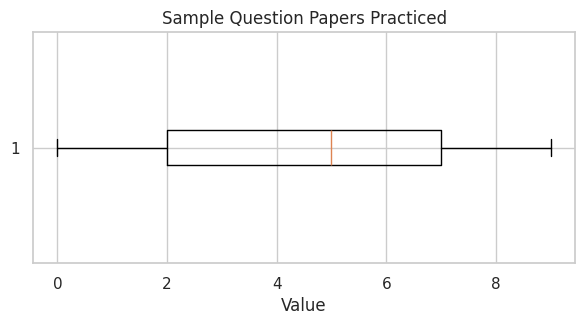

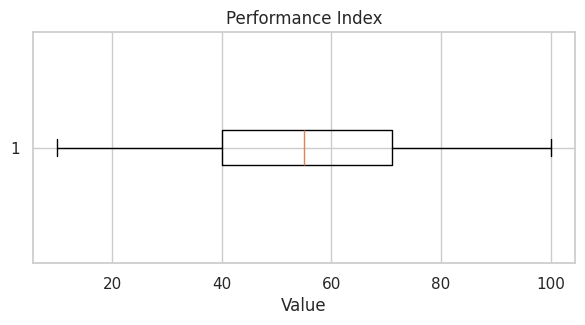

In [12]:
for column in numeric_df:
    plt.figure(figsize=(7, 3))
    plt.boxplot(numeric_df[column].dropna(), vert=False)
    plt.title(column)
    plt.xlabel("Value")
    plt.show()

## 10. Potential outliers: the IQR rule

Investigate flagged records. Keep the original data; do not automatically remove observations. An empty result means no rows were flagged.

In [13]:
iqr = q3 - q1
lower_limits = q1 - 1.5 * iqr
upper_limits = q3 + 1.5 * iqr
outlier_mask = (numeric_df < lower_limits) | (numeric_df > upper_limits)
outlier_summary = pd.DataFrame({
    "Lower limit": lower_limits,
    "Upper limit": upper_limits,
    "Flagged count": outlier_mask.sum()
})
display(outlier_summary.round(3))
display(df.loc[outlier_mask.any(axis=1)].head(10))

,Lower limit,Upper limit,Flagged count
Hours Studied,-3.0,13.0,0
Previous Scores,7.5,131.5,0
Sleep Hours,0.5,12.5,0
Sample Question Papers Practiced,-5.5,14.5,0
Performance Index,-6.5,117.5,0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index


## 11. Compare groups

Compare group sizes, location, spread and overlap. The mean difference is descriptive and does not establish causality.

,count,mean,median,std,IQR
Extracurricular Activities,,,,,
No,5052,54.759,55.0,19.152,30.0
Yes,4948,55.701,55.0,19.264,30.0


Mean difference (Yes - No): 0.9423777675793445


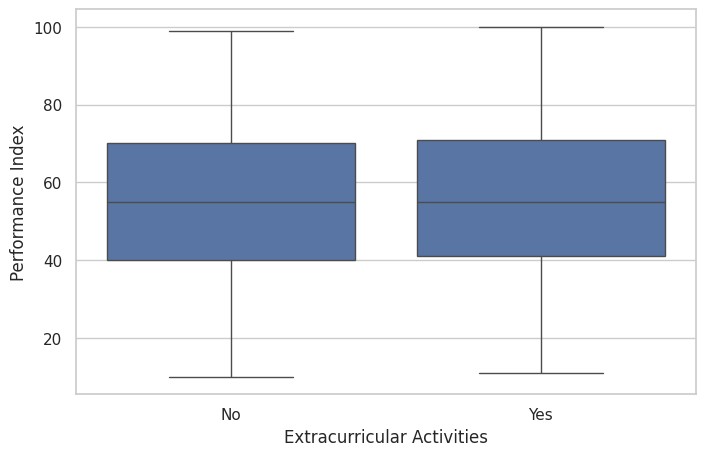

In [14]:
group_column = "Extracurricular Activities"
target = "Performance Index"
groups = df.groupby(group_column)[target]
group_summary = groups.agg(["count", "mean", "median", "std"])
group_summary["IQR"] = groups.quantile(0.75) - groups.quantile(0.25)
display(group_summary.round(3))
print("Mean difference (Yes - No):", group_summary.loc["Yes", "mean"] - group_summary.loc["No", "mean"])
sns.boxplot(data=df, x=group_column, y=target, order=["No", "Yes"])
plt.show()

## 12. Scatterplots and local smoothing

Both examples use local linear fits without robust iterations. LOWESS and LOESS implementations differ, so curves need not be identical. Repeated x values are common; evaluate at distinct x values. Very small spans may fail when too few distinct predictor values enter a neighborhood.

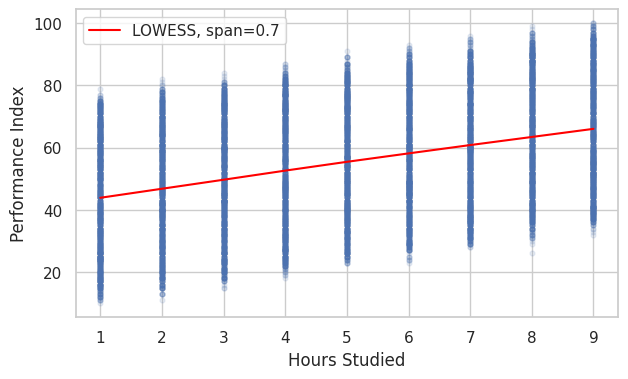

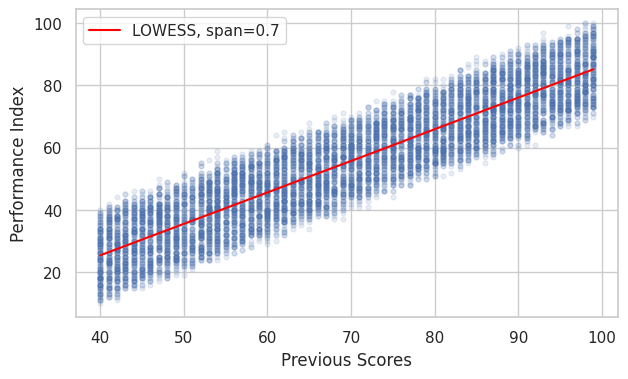

In [15]:
predictors = ["Hours Studied", "Previous Scores"]
span = 0.7
for predictor in predictors:
    pair_data = df[[predictor, target]].dropna()
    x = pair_data[predictor]
    y = pair_data[target]
    x_grid = np.sort(x.unique())
    trend = lowess(y, x, frac=span, it=0, xvals=x_grid)
    plt.figure(figsize=(7, 4))
    plt.scatter(x, y, alpha=0.12, s=12)
    plt.plot(x_grid, trend, color="red", label=f"LOWESS, span={span}")
    plt.xlabel(predictor)
    plt.ylabel(target)
    plt.legend()
    plt.show()

## 13. Compare smoothing spans

Smaller spans reveal more local detail. On approximately linear data, the curves may be very similar.

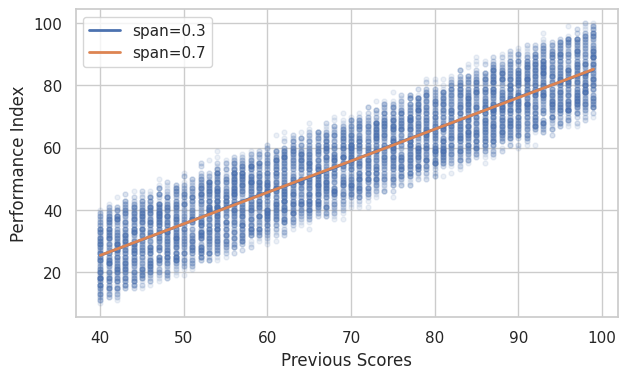

In [16]:
pair_data = df[["Previous Scores", target]].dropna()
x = pair_data["Previous Scores"]
y = pair_data[target]
x_grid = np.sort(x.unique())
plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.1, s=12)
for span in [0.3, 0.7]:
    trend = lowess(y, x, frac=span, it=0, xvals=x_grid)
    plt.plot(x_grid, trend, linewidth=2, label=f"span={span}")
plt.xlabel("Previous Scores")
plt.ylabel(target)
plt.legend()
plt.show()

## 14. Correlation for one pair

Pearson measures linear association; Spearman and Kendall measure monotonic association. Their magnitudes are not interchangeable. Before applying this code to other data, check that selected variables vary and enough complete observations remain.

In [17]:
# Use one common complete dataset for all correlation calculations.
complete_data = numeric_df.replace([np.inf, -np.inf], np.nan).dropna()
print("Complete observations:", len(complete_data))
x = complete_data["Hours Studied"]
y = complete_data[target]
print("Pearson:", x.corr(y, method="pearson"))
print("Spearman:", x.corr(y, method="spearman"))
print("Kendall:", x.corr(y, method="kendall"))

Complete observations: 10000
Pearson: 0.3737303506987236
Spearman: 0.3523946661317077
Kendall: 0.25471937486813717


## 15. Correlation matrices and heatmaps

Use the same observations, variable order and color limits for all methods. Color shows correlation, not significance.

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000,-0.012,0.001,0.017,0.374
Previous Scores,-0.012,1.000,0.006,0.008,0.915
Sleep Hours,0.001,0.006,1.000,0.004,0.048
Sample Question Papers Practiced,0.017,0.008,0.004,1.000,0.043
Performance Index,0.374,0.915,0.048,0.043,1.000


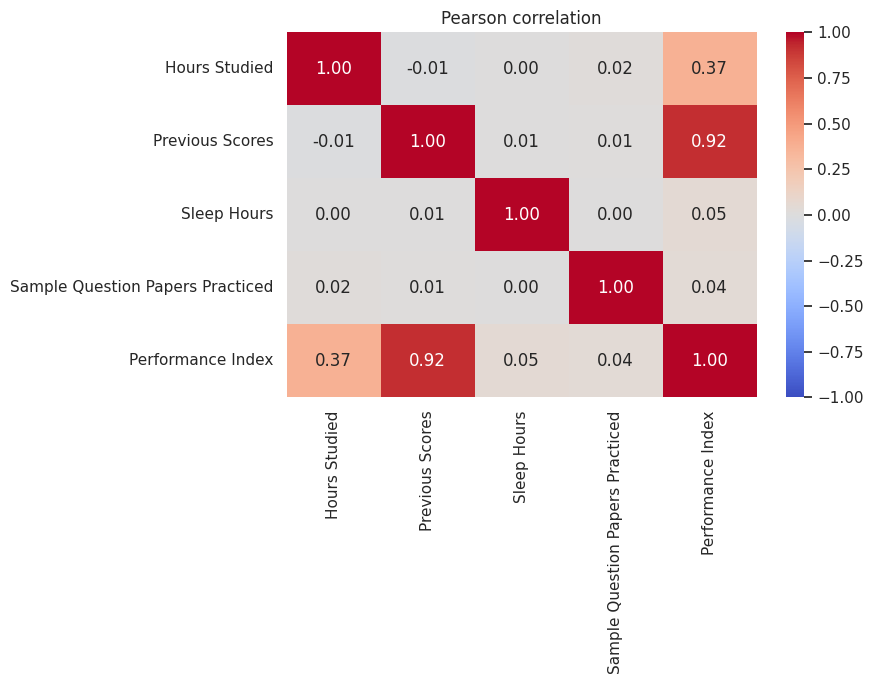

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000,-0.012,0.001,0.017,0.352
Previous Scores,-0.012,1.000,0.006,0.008,0.921
Sleep Hours,0.001,0.006,1.000,0.004,0.045
Sample Question Papers Practiced,0.017,0.008,0.004,1.000,0.040
Performance Index,0.352,0.921,0.045,0.040,1.000


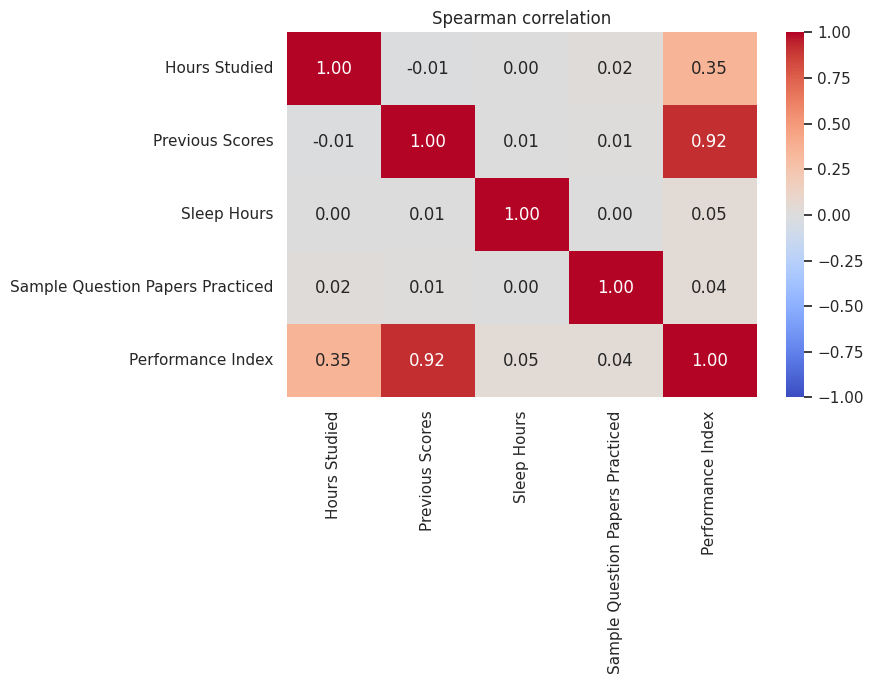

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000,-0.009,0.001,0.013,0.255
Previous Scores,-0.009,1.000,0.004,0.006,0.751
Sleep Hours,0.001,0.004,1.000,0.003,0.033
Sample Question Papers Practiced,0.013,0.006,0.003,1.000,0.029
Performance Index,0.255,0.751,0.033,0.029,1.000


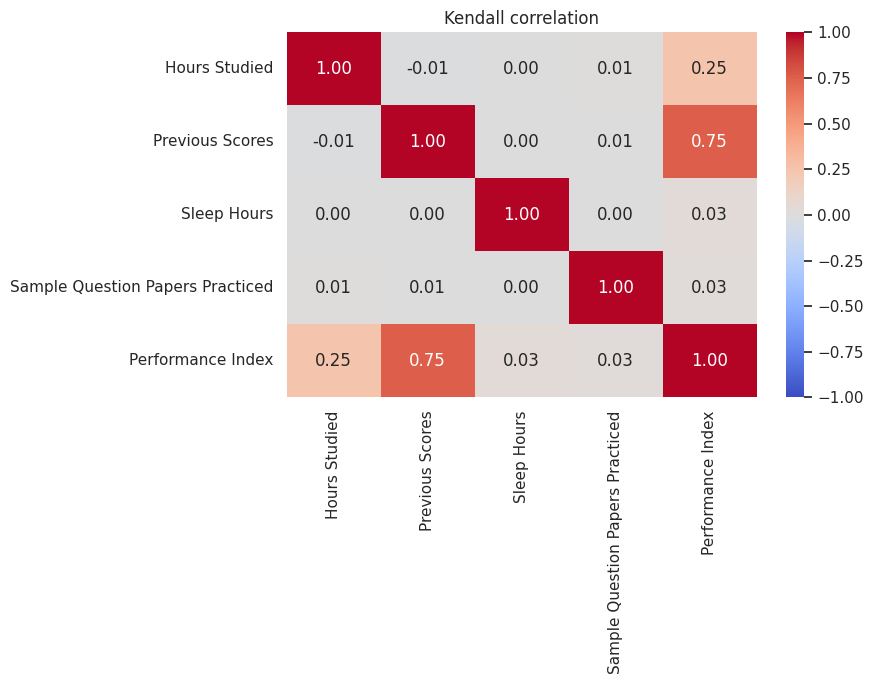

In [18]:
correlation_matrices = {}
for method in ["pearson", "spearman", "kendall"]:
    matrix = complete_data.corr(method=method)
    correlation_matrices[method] = matrix
    display(matrix.round(3))
    plt.figure(figsize=(9, 7))
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
    plt.title(method.capitalize() + " correlation")
    plt.tight_layout()
    plt.show()

## 16. Pearson test and confidence interval: one pair

H0: population Pearson correlation equals zero. The default test is two-sided; the confidence interval uses Fisher transformation. Classical inference assumes independent pairs and, for the exact Pearson null test, bivariate normality. A small p-value does not imply a large or causal effect.

In [19]:
x = complete_data["Hours Studied"]
y = complete_data[target]
test = stats.pearsonr(x, y)
interval = test.confidence_interval(confidence_level=0.95)
print("Sample size:", len(x))
print("Pearson r:", test.statistic)
print("Two-sided p-value:", test.pvalue)
print("95% confidence interval:", interval.low, interval.high)

Sample size: 10000
Pearson r: 0.3737303506987237
Two-sided p-value: 0.0
95% confidence interval: 0.3567434769790036 0.39047017162350767


## 17. Multiple Pearson tests and BH correction

The test family is defined before correction: four predictor-target Pearson tests. This is a focused lecture example replacing the original 10 pairs per method. The student assignment uses six Pearson tests with MEDV as one family. Confidence intervals here are individual 95% intervals, not adjusted simultaneous intervals. BH controls false discovery rate under its usual independence or suitable positive-dependence conditions.

In [20]:
# Family: all four numerical predictors versus Performance Index.
predictors = complete_data.columns.drop(target)
records = []
for predictor in predictors:
    test = stats.pearsonr(complete_data[predictor], complete_data[target])
    interval = test.confidence_interval(confidence_level=0.95)
    records.append([predictor, len(complete_data), test.statistic,
                    interval.low, interval.high, test.pvalue])
results = pd.DataFrame(records, columns=["Variable", "N", "r", "CI_lower", "CI_upper", "p_value"])
results["p_BH"] = multipletests(results["p_value"], method="fdr_bh")[1]
results["Reject_H0_BH"] = results["p_BH"] < 0.05
# Keep p-values unrounded: very small values should not be displayed as 0.000.
display(results)

,Variable,N,r,CI_lower,CI_upper,p_value,p_BH,Reject_H0_BH
0,Hours Studied,10000,0.373730,0.356743,0.390470,0.000000,0.000000,True
1,Previous Scores,10000,0.915189,0.911947,0.918317,0.000000,0.000000,True
2,Sleep Hours,10000,0.048106,0.028533,0.067642,0.000001,0.000002,True
3,Sample Question Papers Practiced,10000,0.043268,0.023688,0.062815,0.000015,0.000015,True


## 18. Visualize Pearson uncertainty

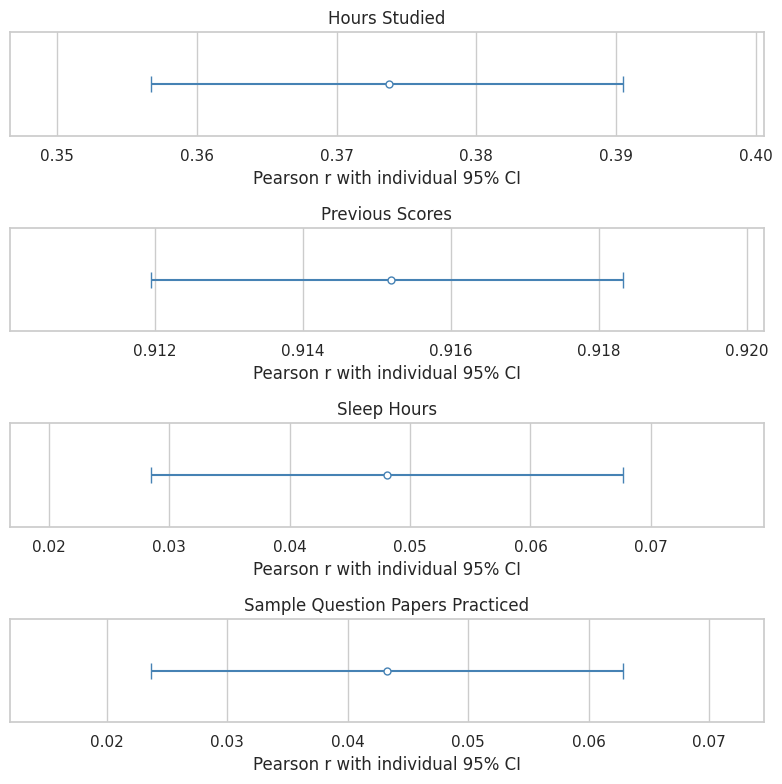

In [21]:
fig, axes = plt.subplots(
    len(results), 1,
    figsize=(8, 2 * len(results)),
    squeeze=False
)

for ax, (_, row) in zip(axes.flat, results.iterrows()):
    ax.errorbar(
        row["r"], 0,
        xerr=[[row["r"] - row["CI_lower"]],
              [row["CI_upper"] - row["r"]]],
        fmt="o",
        markersize=5,
        markerfacecolor="white",
        color="steelblue",
        capsize=6
    )

    margin = (row["CI_upper"] - row["CI_lower"]) * 0.3
    ax.set_xlim(row["CI_lower"] - margin, row["CI_upper"] + margin)
    ax.set_title(row["Variable"])
    ax.set_yticks([])
    ax.set_xlabel("Pearson r with individual 95% CI")

plt.tight_layout()
plt.show()

## Interpretation and transfer to other data

- Describe typical values, variability and distribution shapes.
- Investigate flagged observations without automatically deleting them.
- Compare group sizes and distributions as well as averages.
- Inspect scatterplots before interpreting correlation.
- Report association magnitude, uncertainty and adjusted p-values together.
- Observed associations do not establish causality.

For the house-data assignment, change the filename, select the seven numerical variables from the slides, set target to MEDV, and use CHAS groups 0 and 1. Update the scatterplot predictors and define the six predictor-target Pearson tests as the BH family. Check types, missingness, nonconstant variables and sample size first. LOWESS and LOESS can differ numerically.

Run all cells before exporting with Print → Save as PDF.